# 01 — Data Inspection

## Objective

This notebook documents the initial data-inspection and exploratory data analysis stage of the Digital Twin for Diabetes project.

The project investigates whether recent physiological time-series data, combined with static patient characteristics, can help predict the onset of a qualifying hyperglycemic event within the next 30 minutes.

Before constructing prediction windows or training machine learning models, we first examine the structure, quality, temporal resolution, and characteristics of the available data.

### Objectives of this notebook

- Inspect the structure and features of the patient time-series data.
- Verify timestamps and sampling frequency.
- Examine physiological, activity, insulin, and carbohydrate-related measurements.
- Investigate distributions, correlations, and temporal patterns.
- Summarize observations that inform subsequent preprocessing and modeling decisions.

**Scope:** This notebook focuses on data inspection and exploratory analysis. Subsequent modeling stages use the observations from this analysis to define prediction targets, construct time-series windows, and evaluate candidate models.

##  Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import sklearn

print("Environment ready!!")


Environment ready!!


## Dataset Overview

The dataset contains time-series physiological measurements collected from participants with Type 1 diabetes during free-living conditions.

Each participant's data is stored in a separate CSV file. The observations include glucose measurements, physical activity indicators, heart rate, insulin delivery, and carbohydrate intake.

The dataset also includes static patient characteristics, which can later be combined with the dynamic measurements to represent both the patient's background and their recent physiological state.

In this section, we inspect the available columns, data types, timestamp coverage, and sampling frequency before proceeding with exploratory analysis.

In [13]:
df = pd.read_csv('../data/preprocessed/HUPA0001P (1).csv', sep=";")

In [14]:
df.tail(6)

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
3764,2018-06-26T23:20:00,163.333333,5.59674,70.731707,0.0,0.075,0.0,0.0
3765,2018-06-26T23:25:00,160.666667,5.59674,68.875000,0.0,0.075,0.0,0.0
3766,2018-06-26T23:30:00,158.000000,5.48700,71.621622,0.0,0.075,0.0,0.0
3767,2018-06-26T23:35:00,159.000000,5.70648,71.692308,0.0,0.075,0.0,0.0
3768,2018-06-26T23:40:00,160.000000,5.48700,70.346154,0.0,0.075,0.0,0.0
3769,2018-06-26T23:45:00,161.000000,5.48700,71.437500,0.0,0.075,0.0,0.0


In [ ]:
df['time'] = pd.to_datetime(df['time'])

In [92]:
df['time'].head(10)

0   2018-06-13 21:40:00
1   2018-06-13 21:45:00
2   2018-06-13 21:50:00
3   2018-06-13 21:55:00
4   2018-06-13 22:00:00
5   2018-06-13 22:05:00
6   2018-06-13 22:10:00
7   2018-06-13 22:15:00
8   2018-06-13 22:20:00
9   2018-06-13 22:25:00
Name: time, dtype: datetime64[us]

In [93]:
df.shape

(3770, 8)

In [94]:
df.columns

Index(['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate',
       'bolus_volume_delivered', 'carb_input'],
      dtype='str')

In [95]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3770 entries, 0 to 3769
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   time                    3770 non-null   datetime64[us]
 1   glucose                 3770 non-null   float64       
 2   calories                3770 non-null   float64       
 3   heart_rate              3770 non-null   float64       
 4   steps                   3770 non-null   float64       
 5   basal_rate              3770 non-null   float64       
 6   bolus_volume_delivered  3770 non-null   float64       
 7   carb_input              3770 non-null   float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 235.8 KB


In [12]:
df.describe()

,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
count,3770.000000,3770.000000,3770.000000,3770.000000,3770.000000,3770.000000,3770.000000
mean,143.273519,9.317933,78.073311,27.411141,0.054491,0.071280,0.115119
std,61.326542,5.335985,12.723682,61.259533,0.024162,0.533412,0.986448
min,44.000000,5.383000,51.177801,0.000000,0.000000,0.000000,0.000000
25%,95.375000,5.487000,69.506944,0.000000,0.029167,0.000000,0.000000
50%,129.000000,6.913620,77.186508,0.000000,0.066667,0.000000,0.000000
75%,181.000000,11.412960,86.220221,26.000000,0.075000,0.000000,0.000000
max,366.000000,46.968720,148.897436,595.000000,0.125000,9.100000,13.000000


In [23]:
time_dff = df['time'].diff()

In [24]:
time_dff.value_counts()

time
0 days 00:05:00    3769
Name: count, dtype: int64

## Observations from Initial Data Inspection

The initial inspection was performed on one participant's dataset, `HUPA0001P`.

### 1. Dataset Structure

- The dataset contains **3,770 rows and 8 columns**.
- The columns include timestamps, glucose, calories, heart rate, steps, basal insulin rate, bolus insulin delivery, and carbohydrate input.
- The `time` column was converted to a datetime type, while the seven remaining columns are numerical.
- All eight columns contain 3,770 non-null values, indicating that no missing values were observed in this participant's inspected dataset.

### 2. Temporal Resolution

- The time difference between consecutive observations is consistently **5 minutes**.
- The data therefore provides regularly sampled physiological measurements suitable for subsequent time-series analysis.
- The observed timestamps span approximately 13 days, from June 13 to June 26, 2018.

### 3. Glucose Measurements

- The mean glucose level is approximately **143.27 mg/dL**, with a standard deviation of **61.33 mg/dL**.
- Glucose values range from **44 mg/dL to 366 mg/dL**.
- The median glucose level is **129 mg/dL**, while the 75th percentile is **181 mg/dL**.
- These statistics indicate substantial variation in glucose measurements within this participant's observation period.

### 4. Activity and Physiological Measurements

- Calories have a mean of approximately 9.32, while heart rate averages 78.07.
- Steps have a median of zero, although the maximum recorded value is 595.
- These measurements show that activity-related signals vary considerably across observations.

### 5. Insulin and Carbohydrate Measurements

- The basal insulin rate has a mean of approximately 0.0545 and a maximum of 0.125.
- Both bolus insulin delivery and carbohydrate input have a median of zero.
- However, their maximum values are 9.1 and 13, respectively, indicating that non-zero values also occur in the dataset.

### Initial Takeaway

The inspected participant's dataset contains regularly sampled, non-missing physiological measurements with substantial glucose variability. Activity, insulin delivery, and carbohydrate input provide additional signals that may help characterize the participant's recent physiological state.

These observations apply only to `HUPA0001P`. The remaining participants must be inspected before drawing conclusions about the complete cohort.


## Timestamp and Sampling Frequency

The `time` column was converted from strings to datetime values.

The difference between consecutive timestamps was then calculated
to verify the sampling frequency.

All 3,769 consecutive intervals are exactly 5 minutes apart.
Therefore, the HUPA0001P time series has a regular 5-minute sampling
interval with no detected gaps in this patient record.


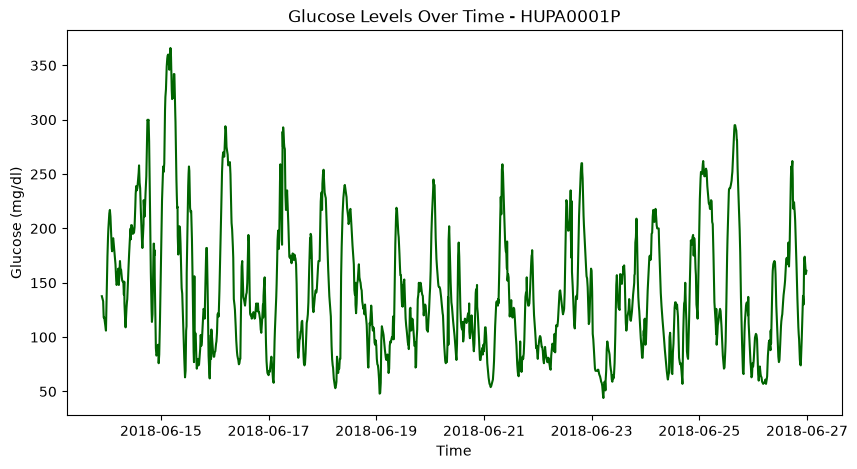

In [42]:
plt.figure(figsize=(10,5))
sns.lineplot(x=df['time'], y=df['glucose'], color='darkgreen')
plt.xlabel("Time")
plt.ylabel("Glucose (mg/dl)")
plt.title("Glucose Levels Over Time - HUPA0001P")
plt.show()

In [45]:
df['carb_input'].value_counts()

carb_input
0.0     3704
7.5       10
2.0        8
10.0       6
9.0        6
3.5        5
11.0       5
4.0        4
12.0       3
3.0        3
8.0        3
1.0        3
13.0       2
1.5        2
2.5        1
5.5        1
4.5        1
11.5       1
7.0        1
8.5        1
Name: count, dtype: int64

In [4]:
carb_events = df[df['carb_input']>0]

In [48]:
carb_events.head()

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
120,2018-06-14 07:40:00,151.000000,6.5220,72.323529,0.0,0.066667,7.50,7.5
170,2018-06-14 11:50:00,196.000000,11.8483,76.222222,22.0,0.025000,1.75,3.5
203,2018-06-14 14:35:00,240.333333,8.2612,79.142857,6.0,0.066667,5.70,11.0
207,2018-06-14 14:55:00,224.333333,7.0655,88.909091,0.0,0.066667,1.50,2.0
282,2018-06-14 21:10:00,180.000000,14.0223,103.205128,0.0,0.075000,3.20,12.0


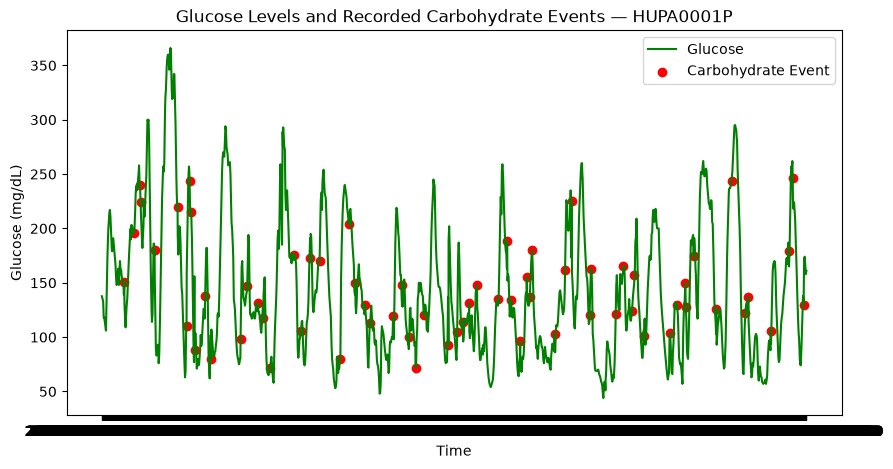

In [19]:
plt.figure(figsize=(10,5))

sns.lineplot(x=df['time'], 
             y=df['glucose'], 
             color='green',
             label='Glucose')

plt.scatter(carb_events['time'], 
            carb_events['glucose'], 
            color='red',
            label='Carbohydrate Event')

plt.xlabel("Time")
plt.ylabel("Glucose (mg/dL)")
plt.title("Glucose Levels and Recorded Carbohydrate Events — HUPA0001P")
plt.legend()

plt.show()


### Observation

Carbohydrate entries are sparse and occur at specific timestamps rather
than continuously. The glucose trajectory does not show a uniform response
following every recorded carbohydrate event, suggesting that glucose
dynamics are influenced by multiple interacting factors such as insulin,
activity, prior glucose levels, and individual physiology.

This supports treating the problem as a multivariate time-series
prediction task rather than relying on carbohydrate intake alone.

In [6]:
df['bolus_volume_delivered'].value_counts()

bolus_volume_delivered
0.000    3661
0.500      11
1.500       6
0.700       6
5.700       4
1.300       4
0.800       4
7.500       3
3.300       3
1.000       3
1.800       3
0.400       3
1.750       2
3.200       2
2.700       2
5.100       2
3.400       2
1.900       2
4.600       2
3.700       2
1.100       2
2.500       2
2.200       2
1.600       2
0.550       2
6.500       2
0.350       2
2.600       2
2.800       2
2.000       1
9.100       1
4.250       1
0.950       1
6.000       1
2.650       1
0.200       1
5.600       1
3.100       1
5.800       1
2.900       1
3.600       1
2.300       1
5.900       1
4.100       1
0.750       1
2.250       1
3.650       1
1.400       1
3.800       1
3.900       1
0.600       1
2.175       1
4.000       1
2.750       1
Name: count, dtype: int64

In [7]:
bolus_events = df[df['bolus_volume_delivered'] > 0]
bolus_events.head()

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input
120,2018-06-14T07:40:00,151.000000,6.5220,72.323529,0.0,0.066667,7.50,7.5
155,2018-06-14T10:35:00,190.000000,7.7177,71.000000,6.0,0.025000,0.50,0.0
170,2018-06-14T11:50:00,196.000000,11.8483,76.222222,22.0,0.025000,1.75,3.5
203,2018-06-14T14:35:00,240.333333,8.2612,79.142857,6.0,0.066667,5.70,11.0
207,2018-06-14T14:55:00,224.333333,7.0655,88.909091,0.0,0.066667,1.50,2.0


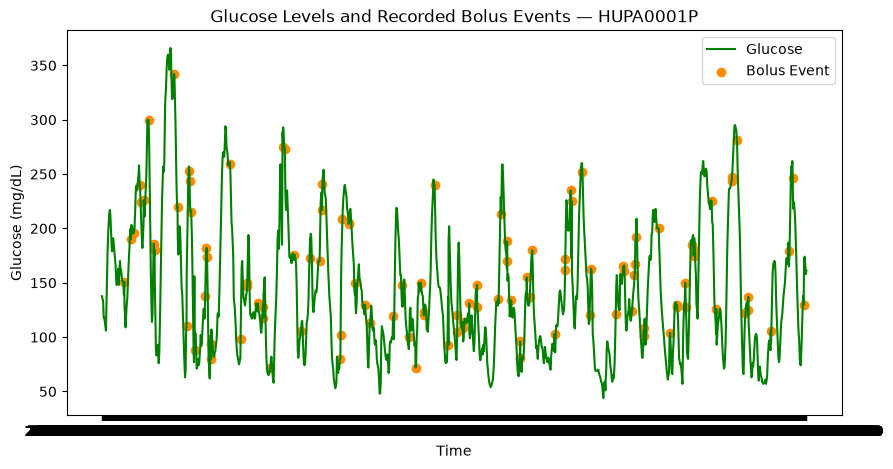

In [18]:
plt.figure(figsize=(10,5))

sns.lineplot(x=df["time"], 
                y=df["glucose"], 
                color='green',
                label="Glucose")

plt.scatter(
    bolus_events["time"],
    bolus_events["glucose"],
    color='darkorange',
    label="Bolus Event"
)

plt.xlabel("Time")
plt.ylabel("Glucose (mg/dL)")
plt.title("Glucose Levels and Recorded Bolus Events — HUPA0001P")
plt.legend()

plt.show()

## Observation

The glucose trajectory shows substantial variation throughout the monitoring period, with repeated rises and falls. Recorded bolus insulin events occur intermittently
 across the time series rather than continuously. The relationship between individual bolus events and glucose changes is not immediately consistent from the visualization alone, indicating that glucose dynamics are influenced by multiple time-dependent factors rather than insulin delivery alone. This supports using a multivariate time-series approach that incorporates glucose history, insulin, carbohydrate intake, activity, and physiological signals.

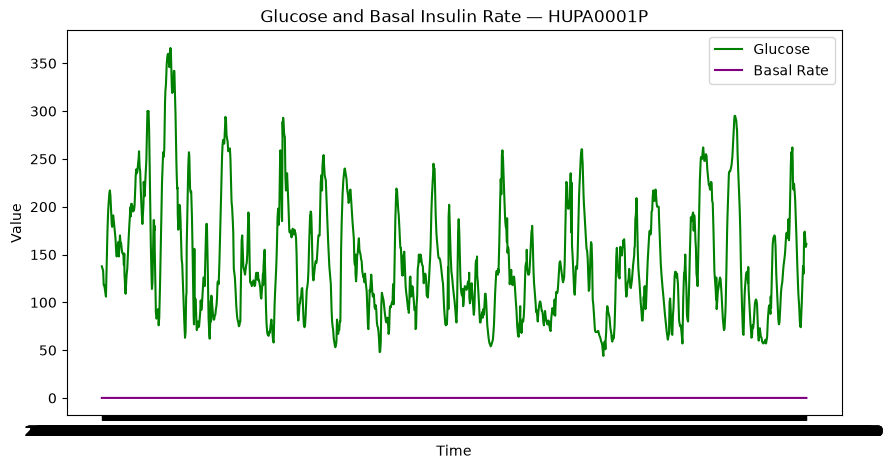

In [20]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=df["time"],
    y=df["glucose"],
    color="green",
    label="Glucose"
)

plt.plot(
    df["time"],
    df["basal_rate"],
    color="purple",
    label="Basal Rate"
)

plt.xlabel("Time")
plt.ylabel("Value")
plt.title("Glucose and Basal Insulin Rate — HUPA0001P")
plt.legend()

plt.show()

### Observation

The glucose signal exhibits substantial temporal variation, whereas the
basal insulin rate changes within a much smaller numerical range. Because
the two variables have very different scales, their relationship cannot be
meaningfully assessed from this direct overlay. Basal insulin should
therefore be analyzed using an appropriate scale or through derived
time-dependent features in later stages of the project.

In [23]:
df['basal_rate'].value_counts()

basal_rate
0.066667    849
0.025000    546
0.075000    534
0.029167    462
0.083333    376
0.050000    284
0.054167    230
0.033333    166
0.100000     83
0.000000     81
0.031667     36
0.091667     36
0.016667     36
0.125000     30
0.037500      6
0.060000      6
0.039167      6
0.073333      3
Name: count, dtype: int64

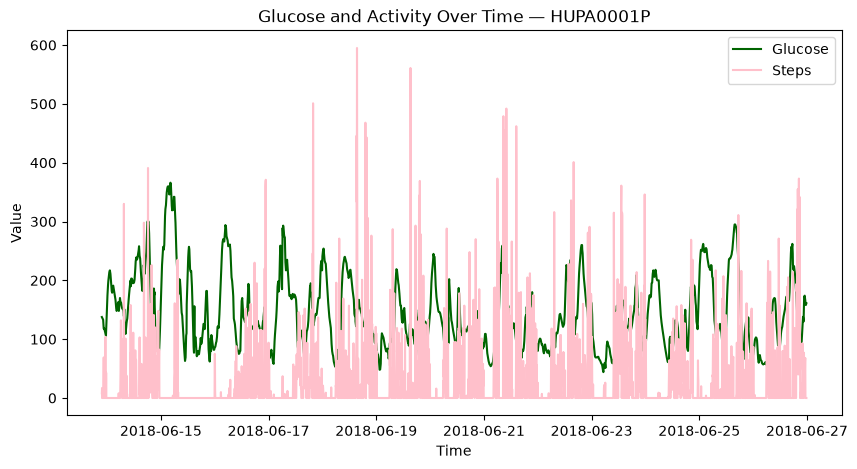

In [47]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=df["time"],
    y=df["glucose"],
    color="darkgreen",
    label="Glucose"
)

sns.lineplot(
    x=df["time"],
    y=df["steps"],
    color="pink",
    label="Steps"
)

plt.xlabel("Time")
plt.ylabel("Value")
plt.title("Glucose and Activity Over Time — HUPA0001P")
plt.legend()

plt.show()

### Observation

Glucose shows substantial variation throughout the monitoring period.
Step counts are highly intermittent, with periods of little or no activity
and occasional bursts of higher activity. Because glucose and steps have
different scales and temporal patterns, their relationship is difficult to
interpret directly from this visualization. A more suitable analysis may
require aggregated or lagged activity features rather than comparing the
two raw signals directly.

In [26]:
df_corr = df.drop(columns='time').corr()

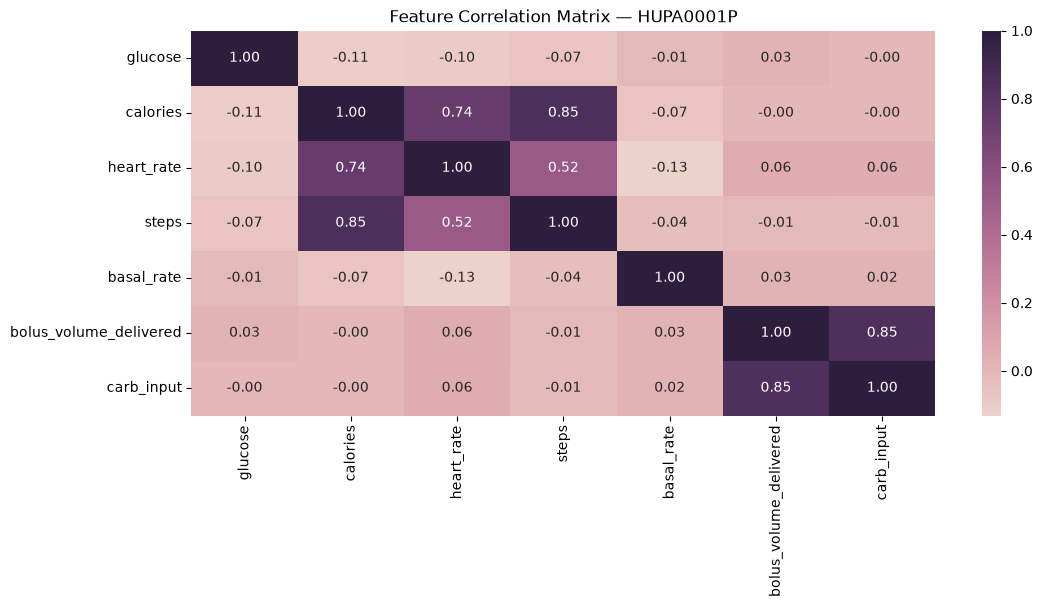

In [32]:
plt.figure(figsize=(12,5))

sns.heatmap(df_corr, 
            cmap=sns.cubehelix_palette(as_cmap=True),
            annot=True,
            fmt=".2f")

plt.title("Feature Correlation Matrix — HUPA0001P")

plt.show()


### Observation

The correlation matrix shows strong positive relationships between calories
and steps (r = 0.85), and between calories and heart rate (r = 0.74).
Bolus insulin delivery and carbohydrate input also show a strong positive
correlation (r = 0.85).

In contrast, glucose has relatively weak contemporaneous linear
correlations with the other variables. This does not imply that these
variables are unimportant for glucose prediction, because glucose
responses may occur with time delays and may depend on combinations of
multiple signals.

Therefore, correlation alone should not be used to select or eliminate
features for the predictive model.

In [36]:
df['hour'] = df['time'].dt.hour

C:\Users\DELL\AppData\Local\Temp\ipykernel_4648\2246027294.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


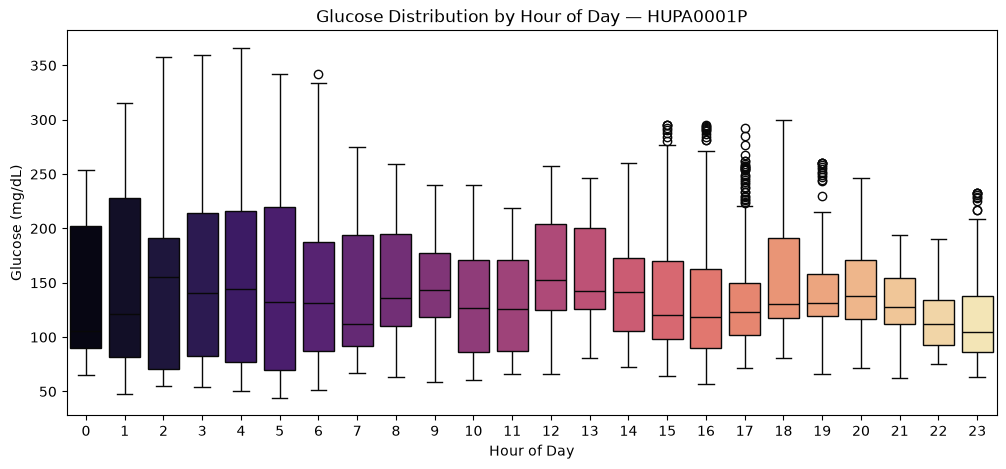

In [39]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    x="hour",
    y="glucose",
    data=df,
    palette='magma'
)

plt.xlabel("Hour of Day")
plt.ylabel("Glucose (mg/dL)")
plt.title("Glucose Distribution by Hour of Day — HUPA0001P")

plt.show()

### Observation

The distribution of glucose varies across different hours of the day,
with differences in median values and spread between several time periods.
Some hours also contain high-glucose observations that appear as outliers
in the boxplots.

These patterns suggest that time of day may provide useful contextual
information for glucose prediction. However, this analysis is based on a
single patient, so the observed hourly patterns should not be generalized
to the wider population without analysis across all participants.

## Cohort-Level Data Inspection

The initial inspection examined one participant's time-series data to understand its structure and temporal resolution. We now extend the inspection to all available participant CSV files.

The dataset contains 25 CSV files, with each file representing a participant's physiological time-series observations.

The objectives of this stage are to:

- Identify all available participant files.
- Compare the number of observations recorded for each participant.
- Examine the temporal coverage of each file.
- Verify the consistency of the sampling interval across participants.
- Identify differences in recording duration and dataset size before constructing the modeling dataset.

In [2]:
from pathlib import Path

In [3]:
processed_dir = Path('../data/preprocessed')

In [4]:
csv_files = list(processed_dir.glob("*.csv"))

In [5]:
len(csv_files)

25

In [ ]:
csv_files

In [ ]:
[f.name for f in csv_files]

In [8]:
patient_summary = []

for file in csv_files:
    df = pd.read_csv(file, sep=";")
    df['time'] = pd.to_datetime(df['time'])
    patient_id = (file.stem).split(" ")[0]
    shape=df.shape
    min = df['time'].min()
    max = df['time'].max()
    null = df.isnull().sum().sum()
    patient_summary.append(
        {
            'patient_id': str(patient_id),
            'rows': shape[0],
            'columns': shape[1],
            'missing_values': null,
            'start_time': min,
            'end_time': max

        }
    )


In [9]:
summary_df = pd.DataFrame(patient_summary)

In [10]:
summary_df.shape

(25, 6)

In [11]:
summary_df['rows'].describe()

count       25.000000
mean      5890.800000
std       8519.568543
min       2290.000000
25%       3184.000000
50%       3812.000000
75%       3895.000000
max      40605.000000
Name: rows, dtype: float64

In [12]:
summary_df['missing_values'].value_counts()

missing_values
0    25
Name: count, dtype: int64

### Cohort-Level Observations

The processed dataset contains 25 patient records, each summarized using
six data-quality and coverage attributes.

The number of observations varies considerably between patients. The
median patient contains 3,812 observations, while the maximum is 46,065
observations. The substantially larger maximum compared with the median
indicates that monitoring coverage is not uniform across participants and
should be investigated before constructing the machine learning dataset.

No missing values were detected in any of the 25 processed patient files.

In [13]:
summary_df['duration'] = summary_df['end_time'] - summary_df['start_time']


In [ ]:
summary_df[['patient_id', 'rows', 'duration']]

### Monitoring Duration

Most participants have approximately 8–14 days of recorded data. However,
HUPA0026P and HUPA0027P have substantially longer monitoring periods of
approximately 90 and 141 days, respectively.

The number of observations for these participants is consistent with their
longer recording durations at the approximately 5-minute sampling
frequency. Therefore, these patients should not be removed solely because
they contain more observations.

However, their substantially greater amount of data may cause them to
contribute more training windows than shorter-recorded participants, so
patient-level balancing and splitting will need to be considered during
model development.

In [15]:
sampling_summary = []

for file in csv_files:
    patient_df = pd.read_csv(file, sep=";")
    patient_df["time"] = pd.to_datetime(patient_df["time"])

    time_diff = patient_df["time"].diff()

    most_common_interval = time_diff.value_counts().idxmax()

    sampling_summary.append({
        "patient_id": file.stem.replace(" (1)", ""),
        "sampling_interval": most_common_interval
    })

In [16]:
sampling_df = pd.DataFrame(sampling_summary)

In [17]:
sampling_df["sampling_interval"].value_counts()

sampling_interval
0 days 00:05:00    25
Name: count, dtype: int64

### Sampling Frequency

The most common time difference between consecutive observations was
calculated for each participant.

All 25 participants have a sampling interval of 5 minutes. Therefore,
the processed cohort has a consistent temporal resolution, which is
important for constructing fixed-length time-series windows for the
predictive model.

Although monitoring duration varies considerably between participants,
the underlying sampling frequency remains consistent.

## Hyperglycemic Event Detection

Before constructing prediction samples, we identify qualifying hyperglycemic events in each participant's glucose time series.

A glucose reading is considered above the selected threshold when it exceeds **180 mg/dL**. However, a single high reading does not automatically qualify as an event.

### How consecutive runs are identified

- **`above_threshold`:** Creates a Boolean series indicating whether each glucose reading exceeds 180 mg/dL.
- **`change`:** Identifies where the Boolean state changes between consecutive readings, such as moving from below the threshold to above it.
- **`run`:** Assigns a unique group identifier to each consecutive sequence of True or False values.
- **`run_counts`:** Calculates the starting Boolean state and number of readings in each run.

A qualifying event is a consecutive run in which glucose remains **strictly above 180 mg/dL for at least six readings**. With five-minute sampling, six consecutive readings span 25 minutes between the first and last timestamps, representing approximately 30 minutes of sampled readings.

The function counts qualifying runs rather than individual high-glucose readings. Consequently, a long continuous high-glucose period is treated as one event, not multiple events.

This function is used to inspect event counts. The next stage identifies the timestamps of qualifying events so they can be used to construct prediction targets.

In [6]:
def count_high_glucose_events(patient_df, threshold=180, min_duration=6):

    above_threshold = patient_df["glucose"] > threshold

    change = above_threshold.ne(above_threshold.shift())

    run = change.cumsum()

    run_counts = (
        patient_df.assign(
            above_threshold=above_threshold,
            run=run
        )
        .groupby("run")["above_threshold"]
        .agg(["first", "size"])
    )

    high_runs = run_counts[
        (run_counts["first"] == True) &
        (run_counts["size"] >= min_duration)
    ]

    return len(high_runs)

In [20]:
count_high_glucose_events(df, threshold=180, min_duration=6)

25

In [45]:
event_summary = []

for file in csv_files:
    patient_df = pd.read_csv(file, sep=";")
    patient_df["time"] = pd.to_datetime(patient_df["time"])

    event_count = count_high_glucose_events(patient_df)

    event_summary.append({
        "patient_id": file.stem.replace(" (1)", ""),
        "events_over_180": event_count
    })

In [46]:
event_summary_df = pd.DataFrame(event_summary)

event_summary_df

In [61]:
event_summary_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   patient_id       25 non-null     str  
 1   events_over_180  25 non-null     int64
dtypes: int64(1), str(1)
memory usage: 532.0 bytes


In [62]:
event_summary_df.describe()

,events_over_180
count,25.000000
mean,38.560000
std,56.395981
min,8.000000
25%,19.000000
50%,25.000000
75%,35.000000
max,294.000000


## Prediction Target and Sliding-Window Construction

The objective is to predict whether a qualifying hyperglycemic event will begin within the next 30 minutes, using the participant's recent physiological history.

### Prediction configuration

| Parameter | Definition |
|---|---|
| Glucose threshold | Strictly above 180 mg/dL |
| Event qualification | At least 6 consecutive readings above the threshold |
| Sampling interval | 5 minutes |
| History window | Previous 2 hours |
| Prediction horizon | Next 30 minutes |
| Window step | 5 minutes |
| Task | Binary classification |

### Identifying event intervals

For each participant, the function identifies qualifying high-glucose runs and records their start and end timestamps. The event start is particularly important because the prediction target concerns the onset of a new qualifying event.

### Constructing input windows

For each prediction time, the model receives the previous two hours of measurements, including the reading at the prediction time. At five-minute sampling, this produces **25 readings per window**, each containing seven dynamic features.

The first prediction time occurs two hours after the participant's first recorded timestamp. Prediction times then advance in five-minute increments, stopping early enough to observe the full 30-minute future horizon.

### Assigning binary labels

- **Positive target (`y = 1`):** A qualifying event begins after the prediction time and within the next 30 minutes.
- **Negative target (`y = 0`):** No qualifying event begins within that future interval.
- **Active-event exclusion:** Prediction times falling within an identified qualifying event interval are excluded, rather than labeled as new event predictions.

The history window includes the prediction-time reading, but the future target begins strictly after that timestamp. This keeps the input history separate from the future event onset being predicted.

The function returns the input windows, binary labels, and participant identifiers for subsequent aggregation and patient-wise data splitting.

In [7]:
history = pd.Timedelta(hours=2)
horizon = pd.Timedelta(minutes=30)
step  = pd.Timedelta(minutes=5)

dynamic_features = [
    "glucose",
    "calories",
    "heart_rate",
    "steps",
    "basal_rate",
    "bolus_volume_delivered",
    "carb_input"
]

In [8]:
def process_patient(file):

    patient_id = file.name.replace(" (1).csv", "")

    df = pd.read_csv(file, sep=";")
    df['time'] = pd.to_datetime(df['time'])

    df["above_threshold"] = df["glucose"] > 180

    change = df["above_threshold"].ne(
    df["above_threshold"].shift()
    )

    df["run"] = change.cumsum()

    run_counts = df.groupby("run")["above_threshold"].agg(
    ["first", "size"]
    )

    high_runs = run_counts[
    (run_counts["first"] == True) &
    (run_counts["size"] >= 6)
    ]
    
    event_intervals = []

    for run_id in high_runs.index:
        run_data = df[df["run"] == run_id]
        
        event_start = run_data["time"].iloc[0]
        event_end = run_data["time"].iloc[-1]
        
        event_intervals.append((event_start, event_end))

    event_starts = [start for start, end in event_intervals]

    first_prediction_time = df["time"].min() + history

    prediction_times = pd.date_range(
    start=first_prediction_time,
    end=df["time"].max() - horizon,
    freq=step
    )
    
    X_patient = []
    y_patient = []
    patient_ids_patient = []
    
    for prediction_time in prediction_times:
        
        inside_event = any(
        event_start <= prediction_time <= event_end
        for event_start, event_end in event_intervals
    )
        if inside_event:
           continue
        
        history_start = prediction_time - history
        history_end = prediction_time
        
        X_window = df[
        (df["time"] >= history_start) &
        (df["time"] <= history_end)
    ]
        X_window = X_window[dynamic_features]
        
        future_end = prediction_time + horizon
        
        label = any(
        prediction_time < event <= future_end
        for event in event_starts
    )
        
        X_patient.append(X_window)
        y_patient.append(int(label))
        patient_ids_patient.append(patient_id)
    
    return X_patient, y_patient, patient_ids_patient


In [13]:
file = csv_files[0]

In [14]:
X_patient, y_patient, patient_ids_patient = process_patient(file)

In [15]:
print(len(X_patient)), 
print(len(y_patient)),
print(len(patient_ids_patient))

2804
2804
2804


## Processing the Complete Participant Cohort

After defining the event-detection and window-construction procedures, we apply the same processing function to all 25 participant CSV files.

For each participant, the pipeline:

1. Loads the physiological time series and converts timestamps to datetime values.
2. Identifies qualifying hyperglycemic event intervals.
3. Constructs two-hour input windows at five-minute intervals.
4. Assigns a binary target based on event onset within the next 30 minutes.
5. Excludes prediction times that fall within qualifying event intervals.
6. Stores the input windows, labels, and corresponding participant identifiers.

The participant-level results are then combined into three collections:

- `X_all`: Dynamic input windows containing seven features across 25 timesteps.
- `y_all`: Binary prediction targets.
- `patient_ids_all`: Participant identifier associated with each sample.

Keeping the participant identifiers alongside the samples is essential for the later patient-wise train, validation, and test split. This helps prevent windows from the same participant from appearing in multiple data splits.

In [9]:
X_all = []
y_all = []
patient_ids_all = []

In [10]:
for file in csv_files:
    X_patient, y_patient, patient_ids_patient = process_patient(file)

    X_all.extend(X_patient)
    y_all.extend(y_patient)
    patient_ids_all.extend(patient_ids_patient)

In [11]:
print(len(X_all))
print(len(y_all))
print(len(patient_ids_all))

print(len(X_all) == len(y_all) == len(patient_ids_all))

102248
102248
102248
True


In [19]:
print(X_all[0].shape)

(25, 7)


In [20]:
print('Positive targets:', y_all.count(1))
print('Negative targets:', y_all.count(0))

Positive targets: 5500
Negative targets: 96748


In [ ]:
pd.Series(patient_ids_all).value_counts().sort_index()

HUPA0001P     2804
HUPA0002P     2470
HUPA0003P     2607
HUPA0004P     1742
HUPA0005P     1580
HUPA0006P     1742
HUPA0007P     1480
HUPA0009P     2118
HUPA0010P     2509
HUPA0011P     2901
HUPA0014P     2688
HUPA0015P     1832
HUPA0016P     2364
HUPA0017P     2553
HUPA0018P     1348
HUPA0019P     1632
HUPA0020P     1850
HUPA0021P     2666
HUPA0022P     3261
HUPA0023P     2425
HUPA0024P     1367
HUPA0025P     3790
HUPA0026P    23880
HUPA0027P    24927
HUPA0028P     3712
Name: count, dtype: int64

## Observations from Cohort-Level Window Construction

### 1. Dataset size

The processing pipeline generated **102,248 prediction samples** across the 25 participants. Each input window has a shape of `(25, 7)`, representing 25 timesteps and seven dynamic features.

### 2. Target distribution

- Positive targets: **5,500**
- Negative targets: **96,748**
- Positive target prevalence: approximately **5.38%**

The resulting classification dataset is imbalanced, with substantially fewer positive event-onset samples than negative samples. This imbalance must be considered during model training and evaluation.

### 3. Variation in participant contributions

The number of samples differs considerably between participants. For example, HUPA0001P contributes 2,804 samples, whereas HUPA0026P and HUPA0027P contribute 23,880 and 24,927 samples, respectively.

These differences reflect variation in recording coverage and the number of eligible prediction windows. Consequently, the pooled dataset contains many more samples from some participants than others.

### 4. Implications for model development

The imbalance between positive and negative targets motivates the use of evaluation metrics such as precision, recall, F1-score, and precision-recall AUC, alongside ROC-AUC.

The unequal contribution of participants also makes patient-wise splitting important. Model performance should be evaluated on participants whose windows were not used during training, rather than relying only on a random split of individual windows.

## Patient Metadata

Alongside the dynamic physiological time-series data, the project includes a metadata table containing static characteristics for each participant.

The metadata provides patient-level context that can be combined with recent physiological measurements to construct a personalized Digital Twin representation.

The available fields include:

- **Patient identifier:** `patient_id`
- **Demographic information:** `gender`, `age_years`
- **Clinical information:** `hba1c_percent`, `diabetes_duration_years`
- **Body measurements:** `weight_kg`, `height_cm`, `bmi`
- **Treatment information:** `treatment`

We inspect the metadata structure and verify that its participant identifiers correspond to those found in the processed time-series data.

In [12]:
metadata = pd.read_csv('../data/metadata/patient_metadata.csv')

In [13]:
metadata.head()

,patient_id,gender,hba1c_percent,age_years,diabetes_duration_years,weight_kg,height_cm,treatment,bmi
0,HUPA0001P,Female,8.2,56.3,15.5,59.0,161,CSII,22.76
1,HUPA0002P,Male,7.1,48.6,36.5,82.4,186,CSII,23.82
2,HUPA0003P,Male,7.3,43.4,12.5,62.0,182,CSII,18.72
3,HUPA0004P,Male,7.8,41.2,8.5,88.0,180,CSII,27.16
4,HUPA0005P,Female,6.9,41.9,39.5,58.5,161,CSII,22.57


In [24]:
metadata.shape

(25, 9)

### Verifying Participant Alignment

Before combining static and dynamic features, we verify that the participant identifiers in the processed time-series samples match those in the metadata table.

This check helps ensure that each prediction window can be associated with the correct patient's static characteristics.

The identifier comparison returns `True`, confirming that both sources contain the same set of participant identifiers. The metadata table contains 25 participants and 9 columns, including the patient identifier.

In [25]:
set(patient_ids_all) == set(metadata['patient_id'])

True

### Preparing Static Patient Features

The `patient_id` column is set as the index of the metadata table so that patient characteristics can be retrieved using participant identifiers.

The remaining eight columns represent static patient features. These values describe relatively stable patient characteristics rather than measurements that change every five minutes.

Later, these features will be encoded and scaled as appropriate, then combined with the dynamic time-series input for the GRU-based Digital Twin model.

In [14]:
static_features = metadata.set_index("patient_id")

In [15]:
static_features.head()

,gender,hba1c_percent,age_years,diabetes_duration_years,weight_kg,height_cm,treatment,bmi
patient_id,,,,,,,,
HUPA0001P,Female,8.2,56.3,15.5,59.0,161,CSII,22.76
HUPA0002P,Male,7.1,48.6,36.5,82.4,186,CSII,23.82
HUPA0003P,Male,7.3,43.4,12.5,62.0,182,CSII,18.72
HUPA0004P,Male,7.8,41.2,8.5,88.0,180,CSII,27.16
HUPA0005P,Female,6.9,41.9,39.5,58.5,161,CSII,22.57


## Preparing the Dynamic Input Tensor

The constructed prediction windows are currently stored as individual window objects. We stack them into a single NumPy array so they can be used by machine learning models.

The resulting tensor has three dimensions:

- **Samples:** 102,248 prediction windows
- **Timesteps:** 25 readings per window
- **Features:** 7 dynamic measurements per reading

The resulting shape is `(102248, 25, 7)`. This format preserves the temporal order of each window and is suitable for sequence models such as GRUs, LSTMs, and one-dimensional CNNs.

In [16]:
X_dynamic = np.stack([window.to_numpy() for window in X_all])

In [29]:
X_dynamic.shape

(102248, 25, 7)

In [17]:
unique_patients = np.unique(patient_ids_all)

len(unique_patients)

25

## Patient-Wise Data Splitting

The dataset contains overlapping time-series windows from the same participants. Randomly splitting individual windows could place data from one participant in both training and evaluation sets, producing overly optimistic estimates of generalization.

To reduce this risk, we split the **unique patient identifiers** into separate training, validation, and test groups before assigning their associated windows.

- **Training set:** Used to fit model parameters and preprocessing transformations.
- **Validation set:** Used for model comparison, hyperparameter decisions, and decision-threshold selection.
- **Test set:** Reserved for final evaluation after model selection.

All windows belonging to a participant remain in the same split. This allows us to evaluate how well the model generalizes to participants it did not encounter during training.

The split is performed at the patient level, not at the individual-window level.

In [18]:
from sklearn.model_selection import train_test_split

train_patients, temp_patients = train_test_split(
    unique_patients,
    test_size=8,
    random_state=42
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=4,
    random_state=42
)

### Patient-Wise Split Summary

The 25 participants were divided into three groups:

- **Training:** 17 participants
- **Validation:** 4 participants
- **Test:** 4 participants

The participant identifiers were split before the corresponding prediction windows were assigned to each group. Boolean masks were then used to select the samples belonging to each split.

This approach ensures that all samples from a participant remain within a single group, reducing the risk of patient-level data leakage between training and evaluation.

The resulting sample counts are:

| Split | Prediction samples |
|---|---:|
| Training | 60,402 |
| Validation | 32,116 |
| Test | 9,730 |
| **Total** | **102,248** |

The unequal sample counts reflect differences in recording duration and the number of eligible prediction windows contributed by individual participants.

In [32]:
print("Train:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

Train: 17
Validation: 4
Test: 4


In [19]:
train_mask = np.isin(patient_ids_all, train_patients)
val_mask = np.isin(patient_ids_all, val_patients)
test_mask = np.isin(patient_ids_all, test_patients)

In [34]:
print(train_mask.sum())
print(val_mask.sum())
print(test_mask.sum())

60402
32116
9730


In [35]:
print(train_mask.sum() + val_mask.sum() + test_mask.sum())


102248


### Creating the Training, Validation, and Test Sets

The dynamic input tensor and binary target array are separated using the patient-wise masks.

Each input sample contains 25 consecutive timesteps and seven dynamic features, while its corresponding target indicates whether a qualifying hyperglycemic event is expected to begin within the next 30 minutes.

The resulting shapes are:

- `X_train`: `(60402, 25, 7)`
- `X_val`: `(32116, 25, 7)`
- `X_test`: `(9730, 25, 7)`

The target arrays contain one binary label per input sample. Participant identifiers are also retained for traceability and patient-level evaluation.

In [20]:
X_train = X_dynamic[train_mask]
X_val = X_dynamic[val_mask]
X_test = X_dynamic[test_mask]

y_train = np.array(y_all)[train_mask]
y_val = np.array(y_all)[val_mask]
y_test = np.array(y_all)[test_mask]

In [37]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(60402, 25, 7)
(32116, 25, 7)
(9730, 25, 7)
(60402,)
(32116,)
(9730,)


In [21]:
patient_ids_train = np.array(patient_ids_all)[train_mask]
patient_ids_val = np.array(patient_ids_all)[val_mask]
patient_ids_test = np.array(patient_ids_all)[test_mask]

In [39]:
print(patient_ids_train.shape)
print(patient_ids_val.shape)
print(patient_ids_test.shape)

(60402,)
(32116,)
(9730,)


## Preparing Static Patient Features

The static metadata contains eight patient-level features:

- **Categorical:** `gender`, `treatment`
- **Numerical:** `hba1c_percent`, `age_years`, `diabetes_duration_years`, `weight_kg`, `height_cm`, `bmi`

The categorical features describe patient categories, while the numerical features represent clinical and demographic measurements.

The metadata is indexed by `patient_id`, allowing the static characteristics of each participant to be aligned with the corresponding dynamic prediction windows.

Because each participant contributes multiple windows, their static characteristics are repeated across that participant's samples. These values provide patient-level context to the model alongside the changing physiological measurements.

In [22]:
static_features.columns

Index(['gender', 'hba1c_percent', 'age_years', 'diabetes_duration_years',
       'weight_kg', 'height_cm', 'treatment', 'bmi'],
      dtype='str')

In [23]:
print(static_features["gender"].unique())
print(static_features["treatment"].unique())

<StringArray>
['Female', 'Male']
Length: 2, dtype: str
<StringArray>
['CSII', 'MDI']
Length: 2, dtype: str


In [24]:
static_train = static_features.loc[patient_ids_train]
static_val = static_features.loc[patient_ids_val]
static_test = static_features.loc[patient_ids_test]

In [43]:
print(static_train.shape)
print(static_val.shape)
print(static_test.shape)

(60402, 8)
(32116, 8)
(9730, 8)


In [25]:
num_features = (static_train.select_dtypes(include=[int,float]).columns)
cat_features = (static_train.select_dtypes(include=[object]).columns)

C:\Users\DELL\AppData\Local\Temp\ipykernel_11552\3041410981.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = (static_train.select_dtypes(include=[object]).columns)


In [53]:
print(num_features)
print(cat_features)

Index(['hba1c_percent', 'age_years', 'diabetes_duration_years', 'weight_kg',
       'height_cm', 'bmi'],
      dtype='str')
Index(['gender', 'treatment'], dtype='str')


### Encoding Categorical Features

Gender and insulin treatment are categorical variables. They are transformed using one-hot encoding so that the model can represent each category numerically without imposing an artificial numerical order.

The encoder is fitted using the training participants' metadata and then applied to the training, validation, and test groups.

The two categorical variables produce four encoded features in total, corresponding to the categories observed in the training data. The encoder uses `handle_unknown="ignore"` to handle categories that were not encountered during fitting.

Fitting the encoder on training data only helps prevent information from the validation and test groups from influencing preprocessing.

In [26]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoder.fit(static_train[["gender", "treatment"]])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [27]:
static_cat_train = encoder.transform(
    static_train[["gender", "treatment"]]
)

static_cat_val = encoder.transform(
    static_val[["gender", "treatment"]]
)

static_cat_test = encoder.transform(
    static_test[["gender", "treatment"]]
)

In [50]:
print(static_cat_train.shape)
print(static_cat_val.shape)
print(static_cat_test.shape)

(60402, 4)
(32116, 4)
(9730, 4)


### Scaling Numerical Static Features

The six numerical patient features have different units and value ranges. For example, age is measured in years, while weight is measured in kilograms and HbA1c is expressed as a percentage.

`StandardScaler` standardizes each numerical feature using the mean and standard deviation learned from the training participants.

The fitted scaler is then applied to the validation and test data without refitting it. This keeps preprocessing consistent across all splits and avoids using evaluation data to estimate scaling parameters.

After scaling, the numerical feature matrices retain six columns per sample.

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [29]:
scaler.fit(static_train[num_features])

StandardScaler()

In [30]:
static_num_train = scaler.transform(
    static_train[num_features]
)

static_num_val = scaler.transform(
    static_val[num_features]
)

static_num_test = scaler.transform(
    static_test[num_features]
)

In [56]:
print(static_num_train.shape)
print(static_num_val.shape)
print(static_num_test.shape)

(60402, 6)
(32116, 6)
(9730, 6)


### Combining Encoded and Scaled Static Features

After preprocessing, the six scaled numerical features are concatenated with the four one-hot encoded categorical features.

This produces a **10-dimensional static feature vector** for each prediction sample.

The resulting matrices have the following shapes:

- `X_static_train`: `(60402, 10)`
- `X_static_val`: `(32116, 10)`
- `X_static_test`: `(9730, 10)`

These static matrices align with their corresponding dynamic input windows and target labels. The final GRU-based Digital Twin model can therefore learn from both recent physiological sequences and static patient characteristics.

In [31]:
X_static_train = np.hstack([
    static_num_train,
    static_cat_train
])

X_static_val = np.hstack([
    static_num_val,
    static_cat_val
])

X_static_test = np.hstack([
    static_num_test,
    static_cat_test
])

In [58]:
print(X_static_train.shape)
print(X_static_val.shape)
print(X_static_test.shape)

(60402, 10)
(32116, 10)
(9730, 10)


## Target Distribution Across Data Splits

Before model training, we inspect the distribution of negative and positive targets in each split.

The overall dataset contains 5,500 positive samples and 96,748 negative samples, so positive event-onset targets represent approximately 5.38% of all samples.

The class distribution is not identical across the training, validation, and test groups because participants have different recording patterns and event frequencies.

This imbalance is important when evaluating the model. Accuracy alone could be misleading, so we also examine precision, recall, F1-score, ROC-AUC, and precision-recall AUC.

Any class-balancing strategy should be applied to the training process only. Validation and test distributions must remain unchanged to provide meaningful evaluation results.

In [59]:
print("Train:")
print(np.bincount(y_train))

print("\nValidation:")
print(np.bincount(y_val))

print("\nTest:")
print(np.bincount(y_test))

Train:
[57655  2747]

Validation:
[30040  2076]

Test:
[9053  677]


## Scaling Dynamic Physiological Features

The dynamic input contains seven physiological features measured over 25 timesteps. These features have different units and numerical ranges, so we standardize them using `StandardScaler`.

To fit the scaler, the training tensor is temporarily reshaped from three dimensions into a two-dimensional array. This allows the scaler to calculate the mean and standard deviation of each feature across the training samples and timesteps.

The scaler is fitted using training data only. The same transformation is then applied to the validation and test sets without refitting, preventing information leakage from the evaluation data.

After scaling, the arrays are reshaped back into their original three-dimensional format so that the temporal structure is preserved for sequence models.

The resulting shapes remain:

- Training: `(60402, 25, 7)`
- Validation: `(32116, 25, 7)`
- Test: `(9730, 25, 7)`

In [32]:
n_train, n_timesteps, n_features = X_train.shape

X_train_2d = X_train.reshape(-1, n_features)

print(X_train_2d.shape)

(1510050, 7)


In [33]:
dynamic_scaler = StandardScaler()

dynamic_scaler.fit(X_train_2d)

StandardScaler()

In [34]:
X_val_2d = X_val.reshape(-1, X_val.shape[-1])
X_test_2d = X_test.reshape(-1, X_test.shape[-1])

In [35]:
X_train_scaled = dynamic_scaler.transform(X_train_2d)
X_val_scaled = dynamic_scaler.transform(X_val_2d)
X_test_scaled = dynamic_scaler.transform(X_test_2d)

In [36]:
X_train_scaled = X_train_scaled.reshape(X_train.shape)
X_val_scaled = X_val_scaled.reshape(X_val.shape)
X_test_scaled = X_test_scaled.reshape(X_test.shape)

In [65]:
print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(60402, 25, 7)
(32116, 25, 7)
(9730, 25, 7)


## Baseline Feature Engineering

To establish a conventional machine-learning baseline, we summarize each two-hour physiological window into 12 engineered features.

The features include six glucose summaries—latest value, mean, minimum, maximum, standard deviation, and change—along with summaries of calories, heart rate, steps, basal insulin delivery, bolus insulin delivery, and carbohydrate input.

This converts each sequence from a matrix of 25 timesteps and seven features into a single 12-dimensional feature vector.

The resulting representation is suitable for models such as Logistic Regression, which expect a fixed-length feature vector rather than a sequential input tensor.

The same feature-engineering function is applied to the training, validation, and test sets.

In [37]:
def create_baseline_features(X):

    glucose = X[:, :, 0]
    calories = X[:, :, 1]
    heart_rate = X[:, :, 2]
    steps = X[:, :, 3]
    basal_rate = X[:, :, 4]
    bolus = X[:, :, 5]
    carbs = X[:, :, 6]

    features = np.column_stack([
        glucose[:, -1],                  # latest glucose
        glucose.mean(axis=1),            # mean glucose
        glucose.min(axis=1),             # minimum glucose
        glucose.max(axis=1),             # maximum glucose
        glucose.std(axis=1),             # glucose variability
        glucose[:, -1] - glucose[:, 0],  # glucose change

        calories.mean(axis=1),
        heart_rate.mean(axis=1),
        steps.sum(axis=1),
        basal_rate.mean(axis=1),
        bolus.sum(axis=1),
        carbs.sum(axis=1)
    ])

    return features

In [38]:
X_baseline_train = create_baseline_features(X_train_scaled)

print(X_baseline_train.shape)

(60402, 12)


In [39]:
X_baseline_val = create_baseline_features(X_val_scaled)
X_baseline_test = create_baseline_features(X_test_scaled)

In [79]:
print(X_baseline_train.shape)
print(X_baseline_val.shape)
print(X_baseline_test.shape)

(60402, 12)
(32116, 12)
(9730, 12)


## Baseline Model: Logistic Regression

We begin with Logistic Regression as a conventional binary-classification baseline. It predicts the probability that a qualifying hyperglycemic event will begin within the next 30 minutes.

The model is trained using the 12 engineered features derived from each physiological window.

Because positive targets represent only a small proportion of the dataset, we use `class_weight="balanced"` to give greater weight to the minority class during training. The maximum iteration count is increased to 1,000 to allow the optimization process sufficient iterations to converge.

The model is fitted using the training set, while the validation set is reserved for evaluating its predictive performance and selecting a suitable decision threshold.

In [80]:
from sklearn.linear_model import LogisticRegression

In [81]:
baseline_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [82]:
baseline_model.fit(
    X_baseline_train,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [83]:
y_val_proba = baseline_model.predict_proba(X_baseline_val)[:, 1]

In [84]:
print(y_val_proba[:10])

[0.18591565 0.33283761 0.57874389 0.8048484  0.91663333 0.95061507
 0.9698418  0.50525054 0.78164688 0.77928582]


## Evaluating Baseline Probability Predictions

The trained Logistic Regression model generates probabilities for the positive class on the validation set. We evaluate these probabilities using two threshold-independent metrics.

- **ROC-AUC:** Measures how well the model ranks positive samples above negative samples across different classification thresholds.
- **PR-AUC (Average Precision):** Summarizes the precision-recall trade-off and is particularly informative when positive targets are relatively rare.

The validation results are:

| Metric | Score |
|---|---:|
| ROC-AUC | 0.8976 |
| PR-AUC | 0.4395 |

These results indicate that the baseline model can distinguish between many positive and negative samples, although its performance must also be assessed at a chosen operating threshold.

In [85]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_val, y_val_proba)

print("Validation ROC-AUC:", roc_auc)

Validation ROC-AUC: 0.8976314175832352


In [86]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_val, y_val_proba)

print("Validation PR-AUC:", pr_auc)

Validation PR-AUC: 0.4395339372559374


## Classification Metrics at the Default Threshold

By default, we classify a sample as positive when its predicted probability is at least 0.5. We evaluate the resulting predictions using precision, recall, F1-score, and the confusion matrix.

At this threshold, the validation results are:

| Metric | Score |
|---|---:|
| Precision | 0.2514 |
| Recall | 0.7803 |
| F1-score | 0.3803 |

The confusion matrix is:

| | Predicted negative | Predicted positive |
|---|---:|---:|
| Actual negative | 25,217 | 4,823 |
| Actual positive | 456 | 1,620 |

The model identifies a substantial proportion of positive samples, but it also produces many false positives. This illustrates why the default 0.5 threshold may not provide the most appropriate balance between precision and recall for this task.

In [87]:
y_val_pred = (y_val_proba >= 0.5).astype(int)

In [88]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Precision: 0.25143566661493094
Recall: 0.7803468208092486
F1: 0.3803263293813828


In [89]:
cm = confusion_matrix(y_val, y_val_pred)

print(cm)

[[25217  4823]
 [  456  1620]]


In [90]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.98      0.84      0.91     30040
           1       0.25      0.78      0.38      2076

    accuracy                           0.84     32116
   macro avg       0.62      0.81      0.64     32116
weighted avg       0.93      0.84      0.87     32116



## Exploring the Classification Decision Threshold

A predicted probability is not automatically a positive classification. The decision threshold determines how high that probability must be before the model predicts a qualifying event.

We examine several thresholds to understand the trade-off between precision and recall:

- A lower threshold generally increases recall but can produce more false positives.
- A higher threshold generally increases precision but can miss more positive events.
- The F1-score combines precision and recall through their harmonic mean.

We then use the validation precision-recall curve to identify the threshold that maximizes the F1-score.

The selected threshold is approximately **0.7405**, with the following validation results:

| Metric | Score |
|---|---:|
| Precision | 0.4317 |
| Recall | 0.5342 |
| F1-score | 0.4775 |

This threshold is selected using validation data, not the test set. It is a model decision threshold, not a clinical glucose threshold or a medically validated safety boundary.

In [91]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

In [92]:
for threshold in thresholds:

    y_pred = (y_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.2 | Precision: 0.152 | Recall: 0.940 | F1: 0.261
Threshold: 0.3 | Precision: 0.179 | Recall: 0.894 | F1: 0.298
Threshold: 0.4 | Precision: 0.212 | Recall: 0.848 | F1: 0.339
Threshold: 0.5 | Precision: 0.251 | Recall: 0.780 | F1: 0.380
Threshold: 0.6 | Precision: 0.313 | Recall: 0.705 | F1: 0.433
Threshold: 0.7 | Precision: 0.390 | Recall: 0.587 | F1: 0.469
Threshold: 0.8 | Precision: 0.469 | Recall: 0.435 | F1: 0.451


In [93]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])

Best threshold: 0.740458580584743
Best F1: 0.4775026861219859
Precision: 0.43168548073180224
Recall: 0.5342003853564548


In [94]:
X_train_scaled.shape

(60402, 25, 7)

In [109]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense

## CNN Model Evaluation — Validation Set

We evaluated two CNN architectures using the same validation set:

- **CNN:** Uses the 2-hour physiological time-series directly.
- **CNN + Engineered Features:** Combines CNN-extracted temporal patterns with 12 manually engineered statistical features.

### Performance Comparison

| Metric | CNN | CNN + Engineered Features |
|---|---:|---:|
| ROC-AUC | 0.8454 | 0.8766 |
| PR-AUC | 0.3416 | 0.3944 |
| Best F1-score | 0.3929 | 0.4124 |
| Optimal Decision Threshold | 0.6957 | 0.8233 |
| Precision | 0.3582 | 0.3375 |
| Recall | 0.4350 | 0.5299 |

### Interpretation

- **ROC-AUC:** The CNN with engineered features achieved a higher ROC-AUC, indicating better overall discrimination between positive and negative cases.
- **PR-AUC:** Adding engineered features improved PR-AUC from 0.3416 to 0.3944, which is particularly relevant because positive events are relatively uncommon.
- **F1-score:** The engineered-feature model achieved a slightly higher F1-score, improving from 0.3929 to 0.4124.
- **Precision:** Precision decreased from 0.3582 to 0.3375, meaning a smaller proportion of its positive predictions were correct.
- **Recall:** Recall increased from 0.4350 to 0.5299, meaning the model identified a larger proportion of actual positive cases.
- **Decision threshold:** Each model's threshold was selected to maximize F1-score on the validation set. The thresholds differ because the models produce different probability distributions.

### Conclusion

Adding engineered features improved the CNN's ROC-AUC, PR-AUC, F1-score, and recall, but slightly reduced precision. The CNN with engineered features identified more positive cases, although it also produced more false-positive predictions relative to its true-positive predictions.

These results suggest that engineered features provide useful additional information to the CNN. However, both models should be compared with the recurrent models before choosing the final architecture. All results reported here are from the validation set; the test set should remain reserved for final evaluation.

In [110]:

cnn = Sequential([
    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        input_shape=(25, 7)
    ),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

d:\digital-twin-diabetes\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [111]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 23, 32)         │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 11, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        11,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,033 (47.00 KB)

 Trainable params: 12,033 (47.00 KB)

 Non-trainable params: 0 (0.00 B)

In [112]:
cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Handling Class Imbalance — Class Weights

The training dataset contains significantly more negative samples than positive samples. To address this imbalance, we calculated balanced class weights using `compute_class_weight()`.

### Calculated Class Weights

| Class | Meaning | Weight |
|---|---|---:|
| 0 | No qualifying hyperglycemic event | 0.5238 |
| 1 | Qualifying hyperglycemic event | 10.9942 |

### Interpretation

- **Class 0:** Receives a lower weight because negative samples are more common.
- **Class 1:** Receives a higher weight because positive samples are much less common.

During training, mistakes involving the minority positive class therefore receive greater weight in the loss calculation. This encourages the model to pay more attention to positive cases instead of favoring the majority class.

We use these weights during model training through `class_weight=class_weights`. The validation and test datasets retain their original class distributions.

**Important:** Class weighting does not balance the dataset itself or guarantee better performance. We evaluate its practical effect using metrics such as precision, recall, F1-score, ROC-AUC, and PR-AUC.

In [52]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {
    0: class_weights[0],
    1: class_weights[1]
}

class_weights

{0: np.float64(0.5238227387043621), 1: np.float64(10.994175464142701)}

In [114]:
history_cnn = cnn.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7260 - loss: 0.5194 - val_accuracy: 0.7757 - val_loss: 0.4249
Epoch 2/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7752 - loss: 0.4307 - val_accuracy: 0.7829 - val_loss: 0.4161
Epoch 3/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7952 - loss: 0.3966 - val_accuracy: 0.8314 - val_loss: 0.3505
Epoch 4/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8095 - loss: 0.3665 - val_accuracy: 0.8771 - val_loss: 0.2817
Epoch 5/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8238 - loss: 0.3470 - val_accuracy: 0.7986 - val_loss: 0.4200
Epoch 6/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8316 - loss: 0.3260 - val_accuracy: 0.8298 - val_loss: 0.3506
Epoch 7/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8383 - loss: 0.3143 - val_accuracy: 0.8475 - val_loss: 0.3281
Epoch 8/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8468 - loss: 0.2982 - val_accuracy: 0.

In [115]:
y_val_proba_cnn = cnn.predict(X_val_scaled).ravel()

1004/1004 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [116]:
y_val_proba_cnn[:10]

array([0.00876906, 0.17152911, 0.21105388, 0.7808311 , 0.8834644 ,
       0.9613231 , 0.79417145, 0.06825467, 0.40535083, 0.42357352],
      dtype=float32)

In [117]:
cnn_roc_auc = roc_auc_score(y_val, y_val_proba_cnn)
cnn_pr_auc = average_precision_score(y_val, y_val_proba_cnn)

print("CNN ROC-AUC:", cnn_roc_auc)
print("CNN PR-AUC:", cnn_pr_auc)

CNN ROC-AUC: 0.8454462049957797
CNN PR-AUC: 0.3415579869547997


In [118]:
precision_cnn, recall_cnn, thresholds_cnn = precision_recall_curve(
    y_val,
    y_val_proba_cnn
)

f1_cnn = 2 * (precision_cnn * recall_cnn) / (
    precision_cnn + recall_cnn + 1e-8
)

best_index_cnn = np.argmax(f1_cnn)

print("Best threshold:", thresholds_cnn[best_index_cnn])
print("Best F1:", f1_cnn[best_index_cnn])
print("Precision:", precision_cnn[best_index_cnn])
print("Recall:", recall_cnn[best_index_cnn])

Best threshold: 0.6956923
Best F1: 0.392864906945918
Precision: 0.3581911939706466
Recall: 0.434971098265896


In [119]:
from tensorflow.keras.layers import Input, Concatenate
from tensorflow.keras.models import Model

In [120]:
dynamic_input = Input(shape=(25,7))
engineered_input = Input(shape=(12,))

In [121]:
x = Conv1D(
    filters=32,
    kernel_size=3,
    activation="relu"
)(dynamic_input)

x = MaxPooling1D(pool_size=2)(x)

x = Flatten()(x)

In [122]:
x.shape

(None, 352)

In [123]:
combined = Concatenate()([x, engineered_input])

In [124]:
combined.shape

(None, 364)

In [125]:
fusion = Dense(32, activation='relu')(combined)

In [126]:
fusion.shape

(None, 32)

In [127]:
output = Dense(1, activation="sigmoid")(fusion)

In [128]:
output.shape

(None, 1)

In [129]:
cnn_engineered = Model(
    inputs=[dynamic_input, engineered_input],
    outputs=output
)

In [130]:
cnn_engineered.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 25, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 23, 32)    │        704 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 11, 32)    │          0 │ conv1d_2[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 352)       │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 364)       │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │     11,680 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,417 (48.50 KB)

 Trainable params: 12,417 (48.50 KB)

 Non-trainable params: 0 (0.00 B)

In [131]:
cnn_engineered.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [132]:
history_cnn_engineered = cnn_engineered.fit(
    [X_train_scaled, X_baseline_train],
    y_train,
    validation_data=(
        [X_val_scaled, X_baseline_val],
        y_val
    ),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7722 - loss: 0.4462 - val_accuracy: 0.8382 - val_loss: 0.3357
Epoch 2/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8158 - loss: 0.3625 - val_accuracy: 0.8386 - val_loss: 0.3409
Epoch 3/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8318 - loss: 0.3351 - val_accuracy: 0.8835 - val_loss: 0.2654
Epoch 4/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8428 - loss: 0.3150 - val_accuracy: 0.8369 - val_loss: 0.3542
Epoch 5/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8496 - loss: 0.2978 - val_accuracy: 0.8589 - val_loss: 0.3190
Epoch 6/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8582 - loss: 0.2805 - val_accuracy: 0.8875 - val_loss: 0.2642
Epoch 7/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8643 - loss: 0.2658 - val_accuracy: 0.8946 - val_loss: 0.2495
Epoch 8/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8703 - loss: 0.2558 - val_accuracy: 0.

In [133]:
y_val_proba_cnn_eng = cnn_engineered.predict(
    [X_val_scaled, X_baseline_val]
).ravel()

1004/1004 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step


In [134]:
roc_auc = roc_auc_score(y_val, y_val_proba_cnn_eng)
pr_auc = average_precision_score(y_val, y_val_proba_cnn_eng)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.8765647890160582
PR-AUC: 0.39441365029324515


In [135]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba_cnn_eng
)

f1 = 2 * (precision * recall) / (precision + recall + 1e-8)

best_idx = np.argmax(f1)

print("Best threshold:", thresholds[best_idx])
print("Best F1:", f1[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])

Best threshold: 0.82332313
Best F1: 0.41237112926646885
Precision: 0.33752684872660327
Recall: 0.5298651252408478


In [95]:
from sklearn.metrics import (roc_auc_score,
                             precision_recall_curve,
                             precision_score, recall_score, f1_score,
                             average_precision_score,
                             classification_report,
                             confusion_matrix
                             )

## Model Selection Strategy — GRU vs. GRU with Static Patient Information

The GRU model using only dynamic physiological features achieved the strongest validation performance among the models evaluated so far.

However, our project aims to build a **personalized Digital Twin** that incorporates both:

- **Dynamic features:** Recent glucose, calories, heart rate, steps, basal insulin rate, bolus insulin delivery, and carbohydrate intake.
- **Static features:** Patient characteristics such as age, gender, HbA1c, diabetes duration, weight, height, BMI, and treatment type.

Therefore, we also developed a hybrid GRU architecture that processes dynamic time-series data through a GRU branch and static patient information through a separate dense neural network branch. The learned representations are then combined to predict the probability of a qualifying hyperglycemic event beginning within the next 30 minutes.

### Why retain the hybrid model?

Although the dynamic-only GRU performed better on several validation metrics, the hybrid model aligns more closely with our intended Digital Twin architecture by incorporating both physiological history and patient-specific context.

The hybrid model is therefore selected for deployment based on the project's architectural requirements, rather than solely on the highest validation score.

The dynamic-only GRU remains an important comparison model. Evaluating both models helps us understand the contribution of static patient information and the trade-offs involved in model selection.

In [47]:
from tensorflow.keras.layers import GRU, Dense
from tensorflow.keras.models import Sequential

In [48]:
gru_model = Sequential([
    GRU(32, input_shape=(25,7)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid' )
])

d:\digital-twin-diabetes\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [50]:
gru_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 32)             │         3,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,025 (19.63 KB)

 Trainable params: 5,025 (19.63 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [53]:
history_gru = gru_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.7895 - loss: 0.4034 - val_accuracy: 0.8402 - val_loss: 0.3471
Epoch 2/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - accuracy: 0.8529 - loss: 0.3156 - val_accuracy: 0.8754 - val_loss: 0.2873
Epoch 3/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - accuracy: 0.8582 - loss: 0.2989 - val_accuracy: 0.8443 - val_loss: 0.3273
Epoch 4/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.8620 - loss: 0.2888 - val_accuracy: 0.8918 - val_loss: 0.2321
Epoch 5/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.8656 - loss: 0.2808 - val_accuracy: 0.8860 - val_loss: 0.2533
Epoch 6/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.8674 - loss: 0.2738 - val_accuracy: 0.8716 - val_loss: 0.2790
Epoch 7/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.8674 - loss: 0.2679 - val_accuracy: 0.9071 - val_loss: 0.2081
Epoch 8/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 41s 43ms/step - accuracy: 0.8715 - loss: 0.2596 - 

In [54]:
y_val_proba_gru = gru_model.predict(X_val_scaled).ravel()

1004/1004 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step


In [55]:
gru_roc_auc = roc_auc_score(y_val, y_val_proba_gru)
gru_pr_auc = average_precision_score(y_val, y_val_proba_gru)

print("GRU ROC-AUC:", gru_roc_auc)
print("GRU PR-AUC:", gru_pr_auc)

GRU ROC-AUC: 0.9282585807234541
GRU PR-AUC: 0.5489152265077495


In [56]:
precision_gru, recall_gru, thresholds_gru = precision_recall_curve(
    y_val,
    y_val_proba_gru
)

f1_gru = 2 * (precision_gru * recall_gru) / (
    precision_gru + recall_gru + 1e-8
)

best_idx_gru = np.argmax(f1_gru)

print("Best threshold:", thresholds_gru[best_idx_gru])
print("Best F1:", f1_gru[best_idx_gru])
print("Precision:", precision_gru[best_idx_gru])
print("Recall:", recall_gru[best_idx_gru])

Best threshold: 0.8279869
Best F1: 0.5831359495252969
Precision: 0.5736253494874185
Recall: 0.5929672447013488


In [57]:
from tensorflow.keras.layers import Input, Concatenate
from tensorflow.keras.models import Model

dynamic_input = Input(shape=(25, 7))
static_input = Input(shape=(10,))

In [59]:
dynamic_branch = GRU(32)(dynamic_input)
static_branch = Dense(16, activation='relu')(static_input)

In [60]:
print(dynamic_branch.shape)
print(static_branch.shape)

(None, 32)
(None, 16)


In [63]:
combined  = Concatenate()([dynamic_branch, static_branch])

In [64]:
combined.shape

(None, 48)

In [65]:
fusion = Dense(32, activation='relu')(combined)

output = Dense(1, activation='sigmoid')(fusion)

In [66]:
gru_static_model = Model(
    inputs=[dynamic_input, static_input],
    outputs=output
)

In [67]:
gru_static_model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 25, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_4 (GRU)         │ (None, 32)        │      3,936 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16)        │        176 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 48)        │          0 │ gru_4[0][0],      │
│ (Concatenate)       │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      1,568 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         33 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,713 (22.32 KB)

 Trainable params: 5,713 (22.32 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
gru_static_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [69]:
history_gru_static = gru_static_model.fit(
    [X_train_scaled, X_static_train],
    y_train,
    validation_data=(
        [X_val_scaled, X_static_val],
        y_val
    ),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.8131 - loss: 0.3778 - val_accuracy: 0.8175 - val_loss: 0.3678
Epoch 2/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8506 - loss: 0.2933 - val_accuracy: 0.8257 - val_loss: 0.3487
Epoch 3/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8594 - loss: 0.2757 - val_accuracy: 0.8631 - val_loss: 0.2992
Epoch 4/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8635 - loss: 0.2682 - val_accuracy: 0.8788 - val_loss: 0.2559
Epoch 5/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.8648 - loss: 0.2609 - val_accuracy: 0.8684 - val_loss: 0.2781
Epoch 6/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8675 - loss: 0.2555 - val_accuracy: 0.8832 - val_loss: 0.2548
Epoch 7/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - accuracy: 0.8714 - loss: 0.2474 - val_accuracy: 0.8825 - val_loss: 0.2533
Epoch 8/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 25s 26ms/step - accuracy: 0.8749 - loss: 0.2409 - 

In [70]:
y_val_proba_gru_static = gru_static_model.predict(
    [X_val_scaled, X_static_val]
).ravel()

1004/1004 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step


In [71]:
roc_auc = roc_auc_score(y_val, y_val_proba_gru_static)
pr_auc = average_precision_score(y_val, y_val_proba_gru_static)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9111071237066057
PR-AUC: 0.4911693943454674


In [72]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba_gru_static
)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

best_idx = f1_scores.argmax()

print("Best threshold:", thresholds[best_idx])
print("Best F1:", f1_scores[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])

Best threshold: 0.74959767
Best F1: 0.5232605961759995
Precision: 0.4568655643421999
Recall: 0.6122350674373795


## Additional Model Experiments

### 1. LSTM Model

We experimented with an LSTM network to evaluate its ability to learn temporal dependencies from the 2-hour physiological history. The architecture consisted of an LSTM layer with 32 units, followed by a dense hidden layer with ReLU activation and a sigmoid output layer for binary classification.

The model was trained using the Adam optimizer, binary cross-entropy loss, and class weights to address class imbalance. Its validation performance was comparable to the GRU-based hybrid model, making it a useful alternative for time-series classification.

### 2. GRU with Static and Engineered Features

We also extended the GRU + Static architecture by incorporating 12 engineered features extracted from each 2-hour observation window. These features summarized glucose statistics and changes, along with activity, heart rate, insulin delivery, and carbohydrate intake.

The model combined three sources of information:
- **Dynamic branch:** GRU-based representation of physiological time-series data.
- **Static branch:** Dense representation of patient-specific characteristics.
- **Engineered features:** Handcrafted statistical summaries of the observation window.

The three representations were concatenated and passed through a dense fusion layer before producing the final event-risk probability.

Although this experiment explored a richer feature representation, it did not outperform the simpler GRU + Static model on the validation metrics we evaluated.

### Conclusion

These experiments allowed us to compare recurrent architectures and investigate whether manually engineered features added value beyond learned temporal representations. We retained the GRU + Static model for deployment because it incorporates both dynamic physiological history and static patient information while keeping the architecture relatively simple.

In [73]:
from tensorflow.keras.layers import LSTM

x = LSTM(32)(dynamic_input)
x = Dense(32, activation='relu')(x)
output = Dense(1, activation='sigmoid')(x)

lstm_model = Model(
    inputs=dynamic_input,
    outputs=output
)

In [74]:
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [75]:
history_lstm = lstm_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.7696 - loss: 0.4154 - val_accuracy: 0.8813 - val_loss: 0.2623
Epoch 2/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.8461 - loss: 0.3121 - val_accuracy: 0.8832 - val_loss: 0.2503
Epoch 3/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8545 - loss: 0.2932 - val_accuracy: 0.8806 - val_loss: 0.2607
Epoch 4/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8619 - loss: 0.2767 - val_accuracy: 0.8355 - val_loss: 0.3520
Epoch 5/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - accuracy: 0.8669 - loss: 0.2653 - val_accuracy: 0.8981 - val_loss: 0.2286
Epoch 6/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.8732 - loss: 0.2534 - val_accuracy: 0.8727 - val_loss: 0.2706
Epoch 7/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.8737 - loss: 0.2488 - val_accuracy: 0.8754 - val_loss: 0.2762
Epoch 8/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 28s 30ms/step - accuracy: 0.8806 - loss: 0.2337 - 

In [76]:
y_val_proba_lstm = lstm_model.predict(X_val_scaled).ravel()

1004/1004 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step


In [77]:
roc_auc_lstm = roc_auc_score(y_val, y_val_proba_lstm)
pr_auc_lstm = average_precision_score(y_val, y_val_proba_lstm)

print("ROC-AUC:", roc_auc_lstm)
print("PR-AUC:", pr_auc_lstm)

ROC-AUC: 0.9142645066693349
PR-AUC: 0.4929683693219781


In [78]:
precision_lstm, recall_lstm, thresholds_lstm = precision_recall_curve(
    y_val,
    y_val_proba_lstm
)

f1_lstm = (
    2 * precision_lstm * recall_lstm /
    (precision_lstm + recall_lstm + 1e-8)
)

best_idx_lstm = f1_lstm.argmax()

print("Best threshold:", thresholds_lstm[best_idx_lstm])
print("Best F1:", f1_lstm[best_idx_lstm])
print("Precision:", precision_lstm[best_idx_lstm])
print("Recall:", recall_lstm[best_idx_lstm])

Best threshold: 0.8273734
Best F1: 0.5151811899083402
Precision: 0.5239043824701195
Recall: 0.5067437379576107


In [79]:
engineered_input = Input(shape=(12,))

dynamic_branch = GRU(32)(dynamic_input)

static_branch = Dense(
    16,
    activation="relu"
)(static_input)

combined = Concatenate()([
    dynamic_branch,
    static_branch,
    engineered_input
])

fusion = Dense(
    32,
    activation="relu"
)(combined)

output = Dense(
    1,
    activation="sigmoid"
)(fusion)

gru_full_model = Model(
    inputs=[
        dynamic_input,
        static_input,
        engineered_input
    ],
    outputs=output
)

In [80]:
gru_full_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 25, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_5 (GRU)         │ (None, 32)        │      3,936 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 16)        │        176 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 60)        │          0 │ gru_5[0][0],      │
│ (Concatenate)       │                   │            │ dense_8[0][0],    │
│                     │                   │            │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 32)        │      1,952 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1)         │         33 │ dense_9[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,097 (23.82 KB)

 Trainable params: 6,097 (23.82 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
gru_full_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [82]:
history_gru_full = gru_full_model.fit(
    [
        X_train_scaled,
        X_static_train,
        X_baseline_train
    ],
    y_train,
    validation_data=(
        [
            X_val_scaled,
            X_static_val,
            X_baseline_val
        ],
        y_val
    ),
    epochs=10,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 19s 18ms/step - accuracy: 0.7891 - loss: 0.4049 - val_accuracy: 0.7625 - val_loss: 0.4853
Epoch 2/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8518 - loss: 0.3008 - val_accuracy: 0.8367 - val_loss: 0.3561
Epoch 3/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.8614 - loss: 0.2830 - val_accuracy: 0.8484 - val_loss: 0.3285
Epoch 4/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - accuracy: 0.8667 - loss: 0.2693 - val_accuracy: 0.8394 - val_loss: 0.3527
Epoch 5/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 22s 24ms/step - accuracy: 0.8713 - loss: 0.2596 - val_accuracy: 0.8421 - val_loss: 0.3463
Epoch 6/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 25s 27ms/step - accuracy: 0.8741 - loss: 0.2503 - val_accuracy: 0.8404 - val_loss: 0.3563
Epoch 7/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 27s 28ms/step - accuracy: 0.8774 - loss: 0.2441 - val_accuracy: 0.8467 - val_loss: 0.3388
Epoch 8/10
944/944 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - accuracy: 0.8809 - loss: 0.2358 - 

In [84]:
y_val_proba_gru_full = gru_full_model.predict(
    [X_val_scaled, X_static_val, X_baseline_val]
).ravel()

1004/1004 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step


In [85]:
roc_auc_full = roc_auc_score(y_val, y_val_proba_gru_full)
pr_auc_full = average_precision_score(y_val, y_val_proba_gru_full)

print("ROC-AUC:", roc_auc_full)
print("PR-AUC:", pr_auc_full)

ROC-AUC: 0.9065545714256393
PR-AUC: 0.4572976341689181


In [86]:
precision_full, recall_full, thresholds_full = precision_recall_curve(
    y_val,
    y_val_proba_gru_full
)

f1_full = (
    2 * precision_full * recall_full /
    (precision_full + recall_full + 1e-8)
)

best_idx_full = f1_full.argmax()

print("Best threshold:", thresholds_full[best_idx_full])
print("Best F1:", f1_full[best_idx_full])
print("Precision:", precision_full[best_idx_full])
print("Recall:", recall_full[best_idx_full])

Best threshold: 0.8447857
Best F1: 0.4989238848258087
Precision: 0.4200988467874794
Recall: 0.6141618497109826


In [88]:
print("Validation patients:", np.unique(patient_ids_val))
print("Number of validation patients:", len(np.unique(patient_ids_val)))

Validation patients: ['HUPA0001P' 'HUPA0015P' 'HUPA0017P' 'HUPA0027P']
Number of validation patients: 4


In [98]:
y_test_proba_gru_static = gru_static_model.predict(
    [X_test_scaled, X_static_test]
).ravel()

305/305 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step


In [99]:
roc_auc_test_static = roc_auc_score(
    y_test,
    y_test_proba_gru_static
)

pr_auc_test_static = average_precision_score(
    y_test,
    y_test_proba_gru_static
)

print("Test ROC-AUC:", roc_auc_test_static)
print("Test PR-AUC:", pr_auc_test_static)

Test ROC-AUC: 0.8555299898953822
Test PR-AUC: 0.3309533592647645


In [100]:
test_threshold_static = 0.74959767

y_test_pred_static = (
    y_test_proba_gru_static >= test_threshold_static
).astype(int)

In [101]:
print("Precision:", precision_score(y_test, y_test_pred_static))
print("Recall:", recall_score(y_test, y_test_pred_static))
print("F1:", f1_score(y_test, y_test_pred_static))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_static))

Precision: 0.2661243463102847
Recall: 0.6765140324963073
F1: 0.38198498748957466

Confusion Matrix:
[[7790 1263]
 [ 219  458]]


## Error Analysis — Understanding the Model's Mistakes

After evaluating our GRU + Static model on unseen patients, we examined its predictions to understand where it succeeds and where it struggles.

### 1. What kinds of mistakes did the model make?

We looked at two types of mistakes:

- **False Positive (FP):** The model predicted that a hyperglycemic event would begin within the next 30 minutes, but no qualifying event began during that period.
- **False Negative (FN):** A qualifying event did begin within the next 30 minutes, but the model failed to predict it.

### 2. What did we observe?

**False positives:** In one example, glucose was initially very high, around 236 mg/dL, but gradually decreased. The model predicted a high risk, even though a qualifying new event did not begin within the forecast window.

**False negatives:** In another example, glucose dropped to around 51 mg/dL before rising again. The model assigned a very low risk, even though a qualifying hyperglycemic event began within the forecast window.

These examples show that a high or unusual glucose reading does not always mean an event is about to begin. The direction and pattern of glucose changes also matter.

### 3. What patterns did we find?

When we compared correctly detected events with missed events, we observed that:

- Correctly detected events generally had a stronger recent increase in glucose.
- Missed events tended to have a much smaller glucose increase during the following 30 minutes.
- Missed events had slightly higher average glucose across the full 2-hour history, but their glucose at the end of the window was lower on average.
- Carbohydrate intake and insulin bolus summaries showed only small differences between detected and missed events.

### 4. Did the model perform equally well for every patient?

No. Its performance varied considerably across the four test patients. For example, it detected most qualifying events for some patients but missed many more for another. The number of false alarms also differed between patients.

This suggests that the same model does not work equally well for every individual's glucose patterns.

### Conclusion

The error analysis helped us understand that the model was generally more successful when an upcoming event was accompanied by a stronger recent rise in glucose. It struggled with some events that developed without a clear upward trend and sometimes raised alarms when glucose was already high but falling.

These findings highlight opportunities to improve the model's ability to recognize different glucose patterns and to evaluate its reliability across individual patients.

In [102]:
for patient in np.unique(patient_ids_test):

    mask = patient_ids_test == patient

    y_true = y_test[mask]
    y_pred = y_test_pred_static[mask]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    print(f"\nPatient: {patient}")
    print(f"Samples: {mask.sum()}")
    print(f"TP: {tp}")
    print(f"FP: {fp}")
    print(f"TN: {tn}")
    print(f"FN: {fn}")


Patient: HUPA0002P
Samples: 2470
TP: 27
FP: 37
TN: 2348
FN: 58

Patient: HUPA0010P
Samples: 2509
TP: 157
FP: 358
TN: 1875
FN: 119

Patient: HUPA0011P
Samples: 2901
TP: 164
FP: 578
TN: 2126
FN: 33

Patient: HUPA0020P
Samples: 1850
TP: 110
FP: 290
TN: 1441
FN: 9


In [103]:
patient = "HUPA0002P"

fp_mask = (
    (patient_ids_test == patient) &
    (y_test == 0) &
    (y_test_pred_static == 1)
)

fn_mask = (
    (patient_ids_test == patient) &
    (y_test == 1) &
    (y_test_pred_static == 0)
)

fp_indices = np.where(fp_mask)[0]
fn_indices = np.where(fn_mask)[0]

print("False positive indices:", fp_indices[:10])
print("False negative indices:", fn_indices[:10])

False positive indices: [335 336 337 338 339 340 341 437 611 858]
False negative indices: [22 23 24 25 26 28 73 74 75 76]


In [104]:
patient = "HUPA0002P"

patient_mask = patient_ids_test == patient

patient_indices = np.where(patient_mask)[0]

fp_global_idx = patient_indices[335]
fn_global_idx = patient_indices[22]

print("FP global index:", fp_global_idx)
print("FN global index:", fn_global_idx)

FP global index: 335
FN global index: 22


In [105]:
fp_window = X_test[fp_global_idx]
fn_window = X_test[fn_global_idx]

print("FP window shape:", fp_window.shape)
print("FN window shape:", fn_window.shape)

FP window shape: (25, 7)
FN window shape: (25, 7)


In [106]:
print("FP glucose:")
print(fp_window[:, 0])

print("\nFN glucose:")
print(fn_window[:, 0])

FP glucose:
[235.85714286 228.92857143 222.         212.         202.
 192.         182.         172.         162.         159.33333333
 156.66666667 154.         148.5        143.         137.5
 132.         126.5        121.         126.66666667 132.33333333
 138.         143.66666667 149.33333333 155.         160.66666667]

FN glucose:
[ 89.44444444  83.33333333  77.22222222  71.11111111  65.
  62.66666667  60.33333333  58.          55.66666667  53.33333333
  51.          58.          65.          72.          79.
  86.          93.          99.         105.         111.
 117.         123.         129.         135.         141.        ]


In [107]:
print("FP probability:", y_test_proba_gru_static[fp_global_idx])
print("FN probability:", y_test_proba_gru_static[fn_global_idx])

FP probability: 0.80867475
FN probability: 0.01994569


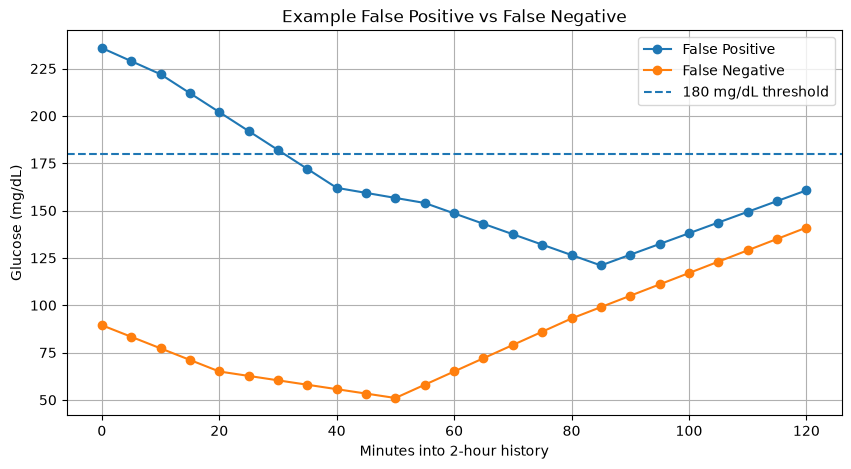

In [108]:
time_steps = np.arange(25) * 5

plt.figure(figsize=(10, 5))

plt.plot(
    time_steps,
    fp_window[:, 0],
    marker="o",
    label="False Positive"
)

plt.plot(
    time_steps,
    fn_window[:, 0],
    marker="o",
    label="False Negative"
)

plt.axhline(
    180,
    linestyle="--",
    label="180 mg/dL threshold"
)

plt.xlabel("Minutes into 2-hour history")
plt.ylabel("Glucose (mg/dL)")
plt.title("Example False Positive vs False Negative")
plt.legend()
plt.grid(True)

plt.show()

In [109]:
glucose_test = X_test[:, :, 0]

glucose_change_30m = (
    glucose_test[:, -1] -
    glucose_test[:, -7]
)

tp_mask = (
    (y_test == 1) &
    (y_test_pred_static == 1)
)

fn_mask = (
    (y_test == 1) &
    (y_test_pred_static == 0)
)

print("TP mean 30-min glucose change:",
      glucose_change_30m[tp_mask].mean())

print("FN mean 30-min glucose change:",
      glucose_change_30m[fn_mask].mean())

print("\nTP median:",
      np.median(glucose_change_30m[tp_mask]))

print("FN median:",
      np.median(glucose_change_30m[fn_mask]))

TP mean 30-min glucose change: 25.16025725751259
FN mean 30-min glucose change: 3.7734564906845343

TP median: 21.0
FN median: 0.5


In [110]:
X_test.shape

(9730, 25, 7)

In [111]:
# Previous 30 minutes = last 7 readings
recent = X_test[:, -7:, :]

tp_mask = (
    (y_test == 1) &
    (y_test_pred_static == 1)
)

fn_mask = (
    (y_test == 1) &
    (y_test_pred_static == 0)
)

# Total carbs in previous 30 minutes
tp_carbs = recent[tp_mask, :, 6].sum(axis=1)
fn_carbs = recent[fn_mask, :, 6].sum(axis=1)

# Total bolus in previous 30 minutes
tp_bolus = recent[tp_mask, :, 5].sum(axis=1)
fn_bolus = recent[fn_mask, :, 5].sum(axis=1)

print("CARBS — previous 30 min")
print("TP mean:", tp_carbs.mean())
print("FN mean:", fn_carbs.mean())
print("TP median:", np.median(tp_carbs))
print("FN median:", np.median(fn_carbs))

print("\nBOLUS — previous 30 min")
print("TP mean:", tp_bolus.mean())
print("FN mean:", fn_bolus.mean())
print("TP median:", np.median(tp_bolus))
print("FN median:", np.median(fn_bolus))

CARBS — previous 30 min
TP mean: 0.5786026200873362
FN mean: 0.4703196347031963
TP median: 0.0
FN median: 0.0

BOLUS — previous 30 min
TP mean: 0.5731659388646289
FN mean: 0.49232876712328766
TP median: 0.0
FN median: 0.0


In [112]:
glucose_test = X_test[:, :, 0]

tp_glucose = glucose_test[tp_mask]
fn_glucose = glucose_test[fn_mask]

print("TP mean glucose across 2-hour history:",
      tp_glucose.mean())

print("FN mean glucose across 2-hour history:",
      fn_glucose.mean())

print("\nTP starting glucose:",
      tp_glucose[:, 0].mean())

print("FN starting glucose:",
      fn_glucose[:, 0].mean())

print("\nTP ending glucose:",
      tp_glucose[:, -1].mean())

print("FN ending glucose:",
      fn_glucose[:, -1].mean())

print("\nTP mean range:",
      (tp_glucose.max(axis=1) - tp_glucose.min(axis=1)).mean())

print("FN mean range:",
      (fn_glucose.max(axis=1) - fn_glucose.min(axis=1)).mean())

TP mean glucose across 2-hour history: 142.8554732416699
FN mean glucose across 2-hour history: 147.2267454497867

TP starting glucose: 144.85770191819253
FN starting glucose: 151.69621958259762

TP ending glucose: 165.9135447172629
FN ending glucose: 147.10423057200657

TP mean range: 71.59210985494914
FN mean range: 81.19178803797753


In [114]:
print(type(gru_static_model))
print(type(dynamic_scaler))
print(type(encoder))
print(type(scaler))

<class 'keras.src.models.functional.Functional'>
<class 'sklearn.preprocessing._data.StandardScaler'>
<class 'sklearn.preprocessing._encoders.OneHotEncoder'>
<class 'sklearn.preprocessing._data.StandardScaler'>


## Saving and Reloading the Digital Twin

After selecting the final GRU + Static model, we saved the trained model and its preprocessing objects so that we could reuse them without retraining.

The following artifacts were saved:

- **`gru_static_model.keras`** — the trained neural network.
- **`dynamic_scaler.pkl`** — scales the time-series physiological features.
- **`static_encoder.pkl`** — encodes categorical patient information.
- **`static_scaler.pkl`** — scales numerical patient information.
- **`config.json`** — stores the prediction threshold, history window, forecast horizon, sampling interval, and feature names.

We then reloaded these artifacts and tested the inference pipeline on a sample containing 25 consecutive readings and a patient profile.

The pipeline transforms both inputs using the saved preprocessing objects, passes them to the trained model, and produces a risk probability. The probability is compared with the validation-selected decision threshold to obtain the final binary prediction.

This makes the trained Digital Twin reusable in our FastAPI backend without repeating model training or preprocessing fitting.

In [115]:
from pathlib import Path

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)

In [116]:
import joblib

joblib.dump(dynamic_scaler, artifacts_dir / "dynamic_scaler.pkl")
joblib.dump(encoder, artifacts_dir / "static_encoder.pkl")
joblib.dump(scaler, artifacts_dir / "static_scaler.pkl")

['artifacts\\static_scaler.pkl']

In [117]:
gru_static_model.save(artifacts_dir / "gru_static_model.keras")

In [118]:
import json

config = {
    "threshold": 0.74959767,
    "history_minutes": 120,
    "horizon_minutes": 30,
    "sampling_minutes": 5,
    "glucose_threshold": 180,
    "event_duration_minutes": 30,
    "dynamic_features": dynamic_features,
    "static_features": list(static_features.columns)
}

with open(artifacts_dir / "config.json", "w") as f:
    json.dump(config, f, indent=4)

In [16]:
print(config['static_features'])

['gender', 'hba1c_percent', 'age_years', 'diabetes_duration_years', 'weight_kg', 'height_cm', 'treatment', 'bmi']


In [119]:
list(artifacts_dir.iterdir())

[WindowsPath('artifacts/config.json'),
 WindowsPath('artifacts/dynamic_scaler.pkl'),
 WindowsPath('artifacts/gru_static_model.keras'),
 WindowsPath('artifacts/static_encoder.pkl'),
 WindowsPath('artifacts/static_scaler.pkl')]

In [3]:
from pathlib import Path
import joblib
import json
from tensorflow.keras.models import load_model

In [4]:
artifacts_dir = Path('artifacts')

model = load_model(artifacts_dir / 'gru_static_model.keras')

dynamic_scaler = joblib.load(artifacts_dir / 'dynamic_scaler.pkl')
encoder = joblib.load(artifacts_dir / 'static_encoder.pkl')
static_scaler = joblib.load(artifacts_dir / 'static_scaler.pkl')  

with open(artifacts_dir / 'config.json') as f:
    config = json.load(f)

In [5]:
print(model.input_shape)
print(dynamic_scaler)
print(encoder)
print(static_scaler)
print(config)

[(None, 25, 7), (None, 10)]
StandardScaler()
OneHotEncoder(handle_unknown='ignore', sparse_output=False)
StandardScaler()
{'threshold': 0.74959767, 'history_minutes': 120, 'horizon_minutes': 30, 'sampling_minutes': 5, 'glucose_threshold': 180, 'event_duration_minutes': 30, 'dynamic_features': ['glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input'], 'static_features': ['gender', 'hba1c_percent', 'age_years', 'diabetes_duration_years', 'weight_kg', 'height_cm', 'treatment', 'bmi']}


In [6]:
categorical_features = ["gender", "treatment"]

numerical_features = [
    "hba1c_percent",
    "age_years",
    "diabetes_duration_years",
    "weight_kg",
    "height_cm",
    "bmi"
]

In [8]:
def preprocess_static(patient):
    categorical_data = encoder.transform(
        patient[categorical_features].to_frame().T
    )

    numerical_data = static_scaler.transform(
        patient[numerical_features].to_frame().T
    )

    static_data = np.concatenate(
        [categorical_data, numerical_data],
        axis=1
    )

    return static_data

In [11]:
patient = pd.Series({
    "gender": "F",
    "hba1c_percent": 7.2,
    "age_years": 25,
    "diabetes_duration_years": 10,
    "weight_kg": 60,
    "height_cm": 165,
    "treatment": "MDI",
    "bmi": 22.0
})

In [12]:
static_data = preprocess_static(patient)

print(static_data.shape)
print(static_data)

(1, 10)
[[ 0.          0.          0.          1.         -0.01793676 -1.47632792
  -0.81313506 -1.06713826 -0.31851674 -1.19139166]]


In [43]:
dynamic_features = list(config['dynamic_features'])

In [44]:
window = df[dynamic_features].iloc[:25].copy()

In [45]:
window.shape

(25, 7)

In [46]:
window_scaled = dynamic_scaler.transform(window)

print(window_scaled.shape)

(25, 7)


d:\digital-twin-diabetes\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [47]:
window_scaled = window_scaled[np.newaxis,:,:]

print(window_scaled.shape)

(1, 25, 7)


In [50]:
probability = model.predict(
    [window_scaled, static_data],
    verbose=0
)

print(probability)
print(probability.shape)

[[0.10406125]]
(1, 1)


In [49]:
risk_probability = float(probability[0][0])

prediction = int(
    risk_probability >= config["threshold"]
)

print("Risk probability:", risk_probability)
print("Prediction:", prediction)

Risk probability: 0.10406124591827393
Prediction: 0


In [ ]:
def predict_risk(window, patient):

    window_scaled = dynamic_scaler.transform(window)

    window_scaled = window_scaled[np.newaxis,:,:]

    static_data = preprocess_static(patient)

    probability = model.predict(
        [window_scaled, static_data],
        verbose=0
    )

    risk_probability = float(probability[0][0])

    prediction = int(
        risk_probability >= config['threshold']
    )

    return {
        "risk_probability": risk_probability,
        "prediction": prediction,
        "threshold": config["threshold"]
        }





In [60]:
result = predict_risk(window,patient)
print(result)

d:\digital-twin-diabetes\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


{'risk_prediction': 0.10406124591827393, 'prediction': 0}


## Conclusion

In this project, we developed a personalized glucose-risk prediction model using physiological time-series data and static patient information from the HUPA-UCM Diabetes Dataset.

We began with data exploration and event definition, followed by patient-level train, validation, and test splits to evaluate generalization to unseen participants. We experimented with multiple approaches, including Logistic Regression, CNN, GRU, and LSTM models, and compared their performance using metrics suitable for an imbalanced binary classification problem.

The GRU model using dynamic features achieved the strongest validation performance among our experiments. However, we selected the **GRU + Static model** for the final Digital Twin because it incorporates both recent physiological patterns and patient-level information, aligning with our project objective.

We also evaluated the final model on the held-out test set and investigated false-positive and false-negative predictions to understand where the model struggled. Finally, we saved the trained model, preprocessing objects, and configuration to support reproducible inference.

The next step was to integrate the saved model into a FastAPI backend and build a frontend that allows users to submit physiological data and view the model's estimated risk.

**Limitations:** This is an experimental proof of concept, not a clinically validated medical device. Its performance may vary between patients, and further validation on larger, independent datasets is necessary before any real-world clinical use.